<a href="https://colab.research.google.com/github/manuelcorrea212/Fisica-Computacional/blob/main/Taller_6_Funciones%2C_Variables_Globales_y_Locales%2C_y_M%C3%B3dulos_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Taller 6: Fórmula semiempírica de masa atómica

### A. Enunciado y requisitos

**Contexto físico.** La masa de un núcleo con $Z$ protones y $A$ nucleones es menor que la suma de las masas de sus componentes: la diferencia es la energía de enlace. En el modelo de la gota líquida (Bethe y Weizsäcker), la energía de enlace **por nucleón** es la suma de cuatro términos:

$$E_B(Z,A) = \underbrace{-\,a_V}_{\text{volumen}} \; + \; \underbrace{a_S\,A^{-1/3}}_{\text{superficie}} \; + \; \underbrace{a_C\,Z^2A^{-4/3}}_{\text{Coulomb}} \; + \; \underbrace{a_A\,\frac{(Z - A/2)^2}{A^2}}_{\text{asimetría}}$$

donde $Z$ es el número de protones, $A$ el número de nucleones (protones más neutrones) y $N = A - Z$ el número de neutrones. Cada término tiene un origen físico:

| Término | Expresión | Origen físico | Efecto |
|---|---|---|---|
| Volumen | $-a_V$ | La fuerza nuclear fuerte es de corto alcance: cada nucleón solo interactúa con sus vecinos inmediatos, así que el enlace es proporcional al número de nucleones y **por nucleón es constante**. | Liga ($<0$) |
| Superficie | $a_S\,A^{-1/3}$ | Los nucleones de la superficie tienen menos vecinos. El núcleo es una esfera de radio $R \propto A^{1/3}$; su superficie es $\propto A^{2/3}$ y, dividida entre $A$, da $A^{-1/3}$. | Resta enlace; pesa más en núcleos livianos |
| Coulomb | $a_C\,Z^2A^{-4/3}$ | Repulsión electrostática entre los $Z$ protones, repartidos en la esfera de radio $R \propto A^{1/3}$: la energía total es $\propto Z^2/A^{1/3}$ y, dividida entre $A$, da $Z^2A^{-4/3}$. | Resta enlace; pesa más en núcleos pesados |
| Asimetría | $a_A\,(Z - A/2)^2/A^2$ | Por el principio de exclusión de Pauli, protones y neutrones ocupan niveles de energía separados: este término por sí solo favorece $Z = N = A/2$, y cualquier exceso de uno de los dos cuesta energía. El mínimo del modelo completo depende también de los otros términos. | Resta enlace si $Z \neq A/2$ |

y la masa atómica aproximada se calcula mediante

$$M(Z,A) = Z\,M_H + (A - Z)\,M_n + A\,E_B(Z,A),$$

donde $Z\,M_H$ es la masa de $Z$ átomos de hidrógeno (cada uno, un protón y un electrón), $(A - Z)\,M_n$ la masa de los $N$ neutrones libres, y $A\,E_B$ la energía de enlace **total**, que es negativa y reduce la masa respecto de los componentes separados. Como se utiliza $M_H$, el resultado incluye la masa de los $Z$ electrones: corresponde aproximadamente a una **masa atómica**, despreciando sus energías de enlace electrónicas.

En las ecuaciones se adopta $c=1$: los símbolos de masa representan su energía equivalente $Mc^2$, expresada en **MeV**. Para expresar la masa como tal, la unidad correspondiente es MeV/$c^2$.

Con esta convención, $E_B < 0$ para un núcleo ligado: cuanto más negativo, más ligado. Las tablas experimentales suelen dar la energía de enlace por nucleón con signo positivo, $B/A = -E_B$.

**Constantes** (O. Zubairi y F. Weber, *Introduction to Computational Physics for Undergraduates*, 2.ª ed., IOP, 2024, problema 7.2):

| $a_V$ | $a_S$ | $a_C$ | $a_A$ | $M_n$ | $M_H$ |
|---|---|---|---|---|---|
| 15.8 MeV | 18.3 MeV | 0.71 MeV | 92.7 MeV | 939.57 MeV | 938.78 MeV |
| coeficiente de volumen | coeficiente de superficie | coeficiente de Coulomb | coeficiente de asimetría | masa del neutrón | masa del átomo de hidrógeno |

Los cuatro coeficientes no se deducen de una teoría: se ajustan a las masas medidas de muchos núcleos. Por eso el modelo se llama *semiempírico*.

**Preguntas que debe responder el programa.**

1. ¿Cuánto vale cada término, la energía de enlace por nucleón y la masa atómica aproximada de los núclidos ${}^{244}$Pu, ${}^{70}$Ge, ${}^{179}$Hf, ${}^{38}$Ar, ${}^{56}$Fe, ${}^{40}$Ca, ${}^{235}$U y ${}^{238}$U?
2. Para cada número de nucleones $A$, ¿qué número de protones $Z$ da el núcleo más ligado? El conjunto de estos puntos define la **curva de máximo enlace del modelo**, relacionada con el valle de estabilidad.
3. ¿Cuál es el núcleo con mayor enlace **por nucleón** en toda esa curva, para el intervalo de $A$ estudiado?

Para un $A$ fijo, se busca el núcleo de menor $E_B(Z,A)$ entre $Z = 1, 2, \dots, A$. En todo el taller, «más ligado» se refiere a mayor enlace **por nucleón**, es decir, a un $E_B$ más negativo.

**Alcance físico de la búsqueda.** Minimizar $E_B$ a $A$ fijo no equivale exactamente a minimizar $M$, porque $M_H$ y $M_n$ son diferentes. La estabilidad frente a transformaciones beta requiere comparar las masas de los isóbaros y considerar los canales de decaimiento. En este taller se conserva únicamente la búsqueda del máximo enlace: **no debe cambiarse el criterio de búsqueda por una minimización de la masa**. Para mantener los nombres de archivo y la arquitectura común, se conservan `valle.dat` y el procedimiento `Z_estable`, entendido aquí como el $Z$ de máximo enlace según el modelo.


**Actividades**

1. Complete el pseudocódigo marco (sección B.1).
2. Escriba, compile y ejecute el programa de Fortran (secciones B.2 y B.3: dos archivos).
3. Escriba el módulo de Python y úselo para la gráfica y el máximo (secciones C.1 a C.4: un módulo y una celda de uso).
4. Ejecute la celda de verificación (sección D). Esta celda no debe modificarse. La entrega debe dar **4/4 PASS**. Esto es necesario, pero no suficiente: también se revisarán el diseño, el código, la gráfica, la interpretación y la sustentación.
5. Responda las preguntas de interpretación (sección E).
6. Elabore el reporte de una página (sección F)

```
MÓDULO del modelo
    constantes: a_V, a_S, a_C, a_A, M_n, M_H
    funciones de los cuatro términos               (entradas: Z y/o A; salida: el término [MeV])
    función E_B(Z, A)                              (usa las cuatro funciones anteriores)
    función M(Z, A)                                (usa E_B)
    procedimiento Z_estable                        (entrada: A; resultados: el Z de máximo enlace y su E_B)
        [COMPLETE 1: cómo se encuentra el Z de menor E_B]
        [JUSTIFIQUE: por qué se usa una subrutina para entregar los dos resultados separados]

PROGRAMA PRINCIPAL (usa el módulo)
    para cada uno de los 8 núcleos, en el orden del enunciado:
        escribir una fila de nucleos.dat: Z, A, los cuatro términos, E_B y M
    para A = 4, 5, ..., 260:
        obtener el Z de máximo enlace y su E_B con Z_estable
        escribir una fila de valle.dat: A, Z, E_B
        [COMPLETE 2: cómo se identifica, durante este ciclo, el núcleo más ligado]
    escribir el núcleo más ligado en maximo.dat
```

#### B.2 Qué debe preparar

La parte B consiste en **dos archivos de Fortran**, que se escriben en las dos celdas de la sección B.3, que ya empiezan con la línea `%%writefile` y el nombre del archivo. La tercera celda, ya escrita, los compila y ejecuta; no la modifique.

| Archivo | Qué contiene | Requisitos |
|---|---|---|
| `taller_nucleo_atomico/modulo_nucleo.f90` | El **módulo** del modelo: <br>• las seis constantes de la tabla del enunciado; <br>• una función para cada uno de los cuatro términos; <br>• una función para $E_B(Z,A)$, que use las cuatro anteriores; <br>• una función para $M(Z,A)$; <br>• el procedimiento que, dado $A$, entrega el $Z$ de máximo enlace y su $E_B$. | R2 a R7 |
| `taller_nucleo_atomico/programa_nucleo.f90` | El **programa principal**: usa el módulo y escribe los tres archivos de resultados. Si necesita procedimientos propios (por ejemplo, para escribir una fila), van después de su `contains`. | R2, R6, R7 |

**Resultados de la parte B**, que escribe el programa al ejecutarse, en la misma carpeta y con el formato de la tabla de la sección A: `nucleos.dat`, `valle.dat` y `maximo.dat`.

**La parte B está terminada cuando** la celda de compilación se ejecuta sin errores, los tres archivos existen y la primera fila de `nucleos.dat` (el ${}^{244}$Pu) tiene $E_B \approx -7.5361$ MeV. Esto es un control inicial; la validación completa se realiza en D.

#### B.3 Código de Fortran

In [ ]:
%%writefile taller_nucleo_atomico/modulo_nucleo.f90
! Taller 6 -- Módulo de la fórmula semiempírica (escriba aquí su módulo)

In [ ]:
%%writefile taller_nucleo_atomico/programa_nucleo.f90
! Taller 6 -- Programa principal (escriba aquí su programa)

In [ ]:
# Compilación y ejecución (NO MODIFICAR): primero el módulo, después el programa.
# Se ejecuta dentro de taller_nucleo_atomico/ para que los .dat queden allí.
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo

### C. Análisis en Python

#### C.1 Qué debe preparar

La parte C consiste en **un módulo de Python** y **una celda que lo usa**. Trabaja solo con los archivos que escribió la parte B: no vuelve a calcular la fórmula.

| Dónde | Qué contiene | Requisitos |
|---|---|---|
| `taller_nucleo_atomico/analisis_nucleo.py` (celda C.3) | Cuatro funciones, cada una con su docstring de entradas y salidas: <br>• una que lea `valle.dat` y devuelva sus tres columnas; <br>• una que encuentre el núcleo más ligado por nucleón recorriendo los datos con un ciclo y un condicional, como en Fortran (sin `min`, `np.min` ni `np.argmin`); <br>• una que escriba ese núcleo en `maximo_python.dat`, con el formato de `maximo.dat`; <br>• una que haga la gráfica de $B/A = -E_B$ contra $A$ con los puntos experimentales de la celda C.2 y la guarde como imagen. | P1 a P3 |
| Celda de uso (C.4) | Importa el módulo (las primeras líneas ya están escritas), llama a las cuatro funciones e imprime el núcleo más ligado. | — |

**Resultados de la parte C**: `taller_nucleo_atomico/maximo_python.dat` y `taller_nucleo_atomico/curva_enlace.png`.

**La parte C está terminada cuando** Python imprime el mismo $A$ y $Z$ que `maximo.dat` y la gráfica muestra la curva del modelo con los diez puntos experimentales.

#### C.2 Datos experimentales

Valores de la energía de enlace por nucleón, $B/A = -E_B$, en MeV (evaluación de masas atómicas AME2020). Use esta celda tal como está. Los puntos representan los núclidos indicados; la curva representa el máximo enlace para cada $A$ según el modelo. No son necesariamente el mismo $Z$, por lo que la comparación gráfica es orientativa. Para una comparación numérica de un núclido concreto, use su mismo $Z$ y $A$.

In [ ]:
# Datos experimentales: (símbolo, Z, A, B/A [MeV]) -- AME2020
EXPERIMENTALES = [
    ("He-4",    2,   4, 7.0739),
    ("C-12",    6,  12, 7.6801),
    ("O-16",    8,  16, 7.9762),
    ("Ca-40",  20,  40, 8.5513),
    ("Fe-56",  26,  56, 8.7903),
    ("Ni-62",  28,  62, 8.7945),
    ("Sn-120", 50, 120, 8.5045),
    ("Pb-208", 82, 208, 7.8675),
    ("U-235",  92, 235, 7.5909),
    ("U-238",  92, 238, 7.5701),
]

#### C.3 Módulo de Python

In [ ]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
"""Taller 6 -- Módulo de análisis (escriba aquí sus cuatro funciones)."""

#### C.4 Uso del módulo

In [ ]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
"""Taller 6 -- Módulo de análisis (escriba aquí sus cuatro funciones)."""

### D. Verificación

La celda siguiente revisa los archivos, sus dimensiones, valores numéricos y coherencia. Los resultados de Fortran deben ser posteriores a sus dos archivos fuente. `maximo_python.dat` debe ser posterior al módulo de análisis y a `valle.dat`. Los cuatro controles informan PASS o FAIL sin detener el notebook. **Esta celda no debe modificarse.**

| Caso | Qué se comprueba |
|---|---|
| 1 | Los ocho núclidos de `nucleos.dat`: orden, cuatro términos, $E_B$ y masa atómica aproximada. |
| 2 | `valle.dat` completo: $A=4,\dots,260$, valores enteros válidos y máximo enlace para cada $A$; incluye la referencia $A=208$, $Z=82$. |
| 3 | Referencia $A=238$, $Z=92$, y coherencia entre el $E_B$ guardado y el modelo en todas las filas de `valle.dat`. |
| 4 | Los máximos de Fortran y Python coinciden con el mínimo global de `valle.dat`; existe una imagen PNG no vacía. |

Las referencias se evalúan en doble precisión con las constantes del enunciado. Por ello pueden diferir en los últimos decimales de una salida publicada con otra precisión. Para ${}^{244}$Pu: $E_B \approx -7.53611738$ MeV y $M \approx 227\,342.0074$ MeV.

**4/4 PASS es necesario, pero no suficiente.** La celda no evalúa la arquitectura del código, el uso de `intent`, la independencia de variables locales, la calidad de la gráfica ni las explicaciones. No consulte su implementación como guía para resolver el algoritmo: utilice los mensajes para localizar qué resultado debe revisar.


### E. Preguntas de interpretación

Responda en celdas de texto, debajo de cada pregunta. Use los resultados de su propio programa. Los cálculos adicionales de esta sección pueden realizarse llamando a los procedimientos de sus módulos; **no cambie el modelo de cuatro términos ni los archivos que utiliza la verificación de D**.

## SOLUCION


### Pregunta B

#### PARTE B.1

```
MÓDULO del modelo
    constantes: a_V, a_S, a_C, a_A, M_n, M_H
    funciones de los cuatro términos               (entradas: Z y/o A; salida: el término [MeV])
    función E_B(Z, A)                              (usa las cuatro funciones anteriores)
    función M(Z, A)                                (usa E_B)
    procedimiento Z_estable                        (entrada: A; resultados: el Z de máximo enlace y su E_B)
        [COMPLETE 1: Se inicializa el Z óptimo en 1 y se calcula su E_B correspondiente.
        Luego, mediante un ciclo desde Z = 2 hasta A, se calcula E_B(Z, A) para cada Z y se compara
        con el menor valor almacenado; si el E_B calculado es menor (más negativo), se actualizan tanto el Z óptimo como el E_B mínimo.]

        [JUSTIFIQUE: Se utiliza una subrutina en lugar de una función porque en Fortran
        una función estándar solo puede devolver un único valor, mientras que aquí
        necesitamos retornar dos resultados distintos de manera simultánea: el valor
        entero del Z óptimo y el valor de precisión doble (real) de su correspondiente energía de enlace E_B.]

PROGRAMA PRINCIPAL (usa el módulo)
    para cada uno de los 8 núcleos, en el orden del enunciado:
        escribir una fila de nucleos.dat: Z, A, los cuatro términos, E_B y M
    para A = 4, 5, ..., 260:
        obtener el Z de máximo enlace y su E_B con Z_estable
        escribir una fila de valle.dat: A, Z, E_B
        
        [COMPLETE 2: Durante cada iteración del ciclo sobre A, comparamos el valor
        de E_B devuelto por Z_estable con una variable de control 'max_EB' (inicializada en un valor alto).
        Si el E_B actual es menor (más negativo), actualizamos 'max_EB' con este
        valor y registramos el número de masa 'A' y el número de protones 'Z' correspondientes.]
    escribir el núcleo más ligado en maximo.dat
```

#### PARTE B.3

In [44]:
import os
os.makedirs("taller_nucleo_atomico", exist_ok=True)
print("Carpeta 'taller_nucleo_atomico' lista.")

Carpeta 'taller_nucleo_atomico' lista.


In [45]:
%%writefile taller_nucleo_atomico/modulo_nucleo.f90
module modulo_nucleo
  implicit none
  integer, parameter :: dp = kind(1.0d0)

  ! Constantes del modelo de Bethe-Weizsäcker (en MeV)
  real(dp), parameter :: a_v = 15.8_dp
  real(dp), parameter :: a_s = 18.3_dp
  real(dp), parameter :: a_c = 0.71_dp
  real(dp), parameter :: a_A = 92.7_dp
  real(dp), parameter :: M_n = 939.57_dp
  real(dp), parameter :: M_H = 938.78_dp

contains

  ! Funciones que calculan directamente el término POR NUCLEÓN (E_B / A)
  real(dp) function term_volumen(A)
    real(dp), intent(in) :: A
    term_volumen = -a_v
  end function term_volumen

  real(dp) function term_superficie(A)
    real(dp), intent(in) :: A
    term_superficie = a_s * A**(-1.0_dp / 3.0_dp)
  end function term_superficie

  real(dp) function term_coulomb(Z, A)
    real(dp), intent(in) :: Z, A
    term_coulomb = a_c * Z**2 * A**(-4.0_dp / 3.0_dp)
  end function term_coulomb

  real(dp) function term_asimetria(Z, A)
    real(dp), intent(in) :: Z, A
    term_asimetria = a_A * (Z - 0.5_dp * A)**2 / A**2
  end function term_asimetria

  ! Energía de enlace por nucleón (negativa por definición: cuanto más negativa, más ligada)
  real(dp) function energia_enlace_por_nucleon(Z, A)
    integer, intent(in) :: Z, A
    real(dp) :: rZ, rA
    rZ = real(Z, dp)
    rA = real(A, dp)
    energia_enlace_por_nucleon = term_volumen(rA) + term_superficie(rA) &
                                  + term_coulomb(rZ, rA) + term_asimetria(rZ, rA)
  end function energia_enlace_por_nucleon

  ! Energía de enlace total: E_B_tot = A * E_B_por_nucleon
  real(dp) function energia_enlace_total(Z, A)
    integer, intent(in) :: Z, A
    energia_enlace_total = real(A, dp) * energia_enlace_por_nucleon(Z, A)
  end function energia_enlace_total

  real(dp) function masa_atomica(Z, A)
    integer, intent(in) :: Z, A
    real(dp) :: rZ, rA, E_B_tot
    rZ = real(Z, dp)
    rA = real(A, dp)
    E_B_tot = energia_enlace_total(Z, A)
    masa_atomica = rZ * M_H + (rA - rZ) * M_n + E_B_tot
  end function masa_atomica

  subroutine Z_estable(A, z_opt, eb_opt)
    integer, intent(in) :: A
    integer, intent(out) :: z_opt
    real(dp), intent(out) :: eb_opt
    integer :: z
    real(dp) :: eb_actual, min_eb

    ! Buscamos el más ligado algebraicamente (el valor de E_B más negativo)
    min_eb = 1.0d10
    z_opt = 1
    do z = 1, A
       eb_actual = energia_enlace_por_nucleon(z, A)
       if (eb_actual < min_eb) then
          min_eb = eb_actual
          z_opt = z
       end if
    end do
    eb_opt = min_eb
  end subroutine Z_estable

end module modulo_nucleo


Overwriting taller_nucleo_atomico/modulo_nucleo.f90


In [46]:
%%writefile taller_nucleo_atomico/programa_nucleo.f90
program programa_nucleo
  use modulo_nucleo, only: dp, energia_enlace_total, energia_enlace_por_nucleon, &
                           masa_atomica, term_volumen, term_superficie, &
                           term_coulomb, term_asimetria, Z_estable
  implicit none

  integer :: u_nucleos, u_valle, u_maximo
  integer :: i, A, Z_opt
  real(dp) :: eb_opt, min_global_eb
  integer :: A_max_global, Z_max_global

  integer, dimension(8) :: lista_Z = (/ 94,  32,  72,  18,  26,  20,  92,  92 /)
  integer, dimension(8) :: lista_A = (/ 244, 70,  179, 38,  56,  40,  235, 238 /)

  real(dp) :: ev, es, ec, ea, eb_tot, eb_nucl, m_at

  ! 1. Generar nucleos.dat (Pregunta 1)
  open(newunit=u_nucleos, file='nucleos.dat', status='replace')
  do i = 1, 8
     Z_opt = lista_Z(i)
     A = lista_A(i)
     ev = term_volumen(real(A, dp))
     es = term_superficie(real(A, dp))
     ec = term_coulomb(real(Z_opt, dp), real(A, dp))
     ea = term_asimetria(real(Z_opt, dp), real(A, dp))
     eb_tot = energia_enlace_total(Z_opt, A)
     eb_nucl = energia_enlace_por_nucleon(Z_opt, A)
     m_at = masa_atomica(Z_opt, A)
     write(u_nucleos, '(i3, i4, 6(es18.10))') Z_opt, A, ev, es, ec, ea, eb_nucl, m_at
  end do
  close(u_nucleos)

  ! 2. Generar valle.dat y maximo.dat (Preguntas 2 y 3)
  open(newunit=u_valle, file='valle.dat', status='replace')
  min_global_eb = 1.0d10
  A_max_global = 0
  Z_max_global = 0

  do A = 4, 260
     call Z_estable(A, Z_opt, eb_opt)
     write(u_valle, '(i4, i4, es18.10)') A, Z_opt, eb_opt
     ! El más ligado es el del valor de E_B más negativo (mínimo algebraico)
     if (eb_opt < min_global_eb) then
        min_global_eb = eb_opt
        A_max_global = A
        Z_max_global = Z_opt
     end if
  end do
  close(u_valle)

  open(newunit=u_maximo, file='maximo.dat', status='replace')
  write(u_maximo, '(i4, i4, es18.10)') A_max_global, Z_max_global, min_global_eb
  close(u_maximo)

  print '(a)', '¡Programa ejecutado con éxito y archivos generados!'
end program programa_nucleo


Overwriting taller_nucleo_atomico/programa_nucleo.f90


In [47]:
# Compilación y ejecución (NO MODIFICAR): primero el módulo, después el programa.
# Se ejecuta dentro de taller_nucleo_atomico/ para que los .dat queden allí.
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo

modulo_nucleo.f90:16:34:

   16 |   real(dp) function term_volumen(A)
      |                                  1
¡Programa ejecutado con éxito y archivos generados!


In [48]:
# Compilamos el módulo y programa de Fortran corregidos, y ejecutamos para actualizar valle.dat
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo

modulo_nucleo.f90:16:34:

   16 |   real(dp) function term_volumen(A)
      |                                  1
¡Programa ejecutado con éxito y archivos generados!


### PREGUNTA A

In [49]:
%%bash
#  Mostrar los resultados de la Pregunta A (nucleos.dat)
echo -e "\n--- RESULTADOS DE LA PREGUNTA A (nucleos.dat) ---"
echo -e "Z   A     T. Volumen         T. Superficie      T. Coulomb         T. Asimetría       B/A (Enlace/A)     Masa Atómica (MeV)"
cat taller_nucleo_atomico/nucleos.dat


--- RESULTADOS DE LA PREGUNTA A (nucleos.dat) ---
Z   A     T. Volumen         T. Superficie      T. Coulomb         T. Asimetría       B/A (Enlace/A)     Masa Atómica (MeV)
 94 244 -1.5800000000E+01  2.9285623920E+00  4.1145999910E+00  1.2207202365E+00 -7.5361173805E+00  2.2734200736E+05
 32  70 -1.5800000000E+01  4.4403623309E+00  2.5201569313E+00  1.7026530612E-01 -8.6692154317E+00  6.5137774920E+04
 72 179 -1.5800000000E+01  3.2471330154E+00  3.6485415825E+00  8.8603273930E-01 -8.0182926629E+00  1.6669087561E+05
 18  38 -1.5800000000E+01  5.4432283957E+00  1.8006331035E+00  6.4196675900E-02 -8.4919418249E+00  3.5366746211E+04
 26  56 -1.5800000000E+01  4.7832353210E+00  2.2402045518E+00  1.1823979592E-01 -8.6583203314E+00  5.2110514061E+04
 20  40 -1.5800000000E+01  5.3509524609E+00  2.0760525941E+00  0.0000000000E+00 -8.3729949449E+00  3.7232080202E+04
 92 235 -1.5800000000E+01  2.9654809304E+00  4.1439087833E+00  1.0915015844E+00 -7.5991087019E+00  2.1894047946E+05
 92 238 -1.58

### PREGUNTA C

In [50]:
# Datos experimentales: (símbolo, Z, A, B/A [MeV]) -- AME2020
EXPERIMENTALES = [
    ("He-4",    2,   4, 7.0739),
    ("C-12",    6,  12, 7.6801),
    ("O-16",    8,  16, 7.9762),
    ("Ca-40",  20,  40, 8.5513),
    ("Fe-56",  26,  56, 8.7903),
    ("Ni-62",  28,  62, 8.7945),
    ("Sn-120", 50, 120, 8.5045),
    ("Pb-208", 82, 208, 7.8675),
    ("U-235",  92, 235, 7.5909),
    ("U-238",  92, 238, 7.5701),
]

#### Parte C.3

In [51]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
# -*- coding: utf-8 -*-
"""Módulo de análisis para el taller de física nuclear y el modelo Bethe-Weizsäcker."""
import numpy as np
import matplotlib.pyplot as plt

def leer_valle(ruta_valle="taller_nucleo_atomico/valle.dat"):
    """Lee el archivo valle.dat y devuelve tres arreglos de numpy (A, Z, E_B)."""
    datos = np.loadtxt(ruta_valle)
    A = datos[:, 0]
    Z = datos[:, 1]
    E_B = datos[:, 2]
    return A, Z, E_B

def encontrar_maximo_enlace(A, Z, E_B):
    """Encuentra el núcleo más ligado por nucleón recorriendo los datos con un ciclo."""
    # Como valle.dat almacena valores de E_B (negativos), el núcleo más ligado es el del valor mínimo (el más negativo)
    min_val = 1e10
    idx_min = -1
    for i in range(len(E_B)):
         if E_B[i] < min_val:
             min_val = E_B[i]
             idx_min = i
    return int(A[idx_min]), int(Z[idx_min]), E_B[idx_min]

def guardar_maximo_python(A_max, Z_max, EB_max, ruta_salida="taller_nucleo_atomico/maximo_python.dat"):
    """Guarda el núcleo más ligado en el archivo de texto especificado."""
    with open(ruta_salida, "w") as f:
        f.write(f"{A_max:4d} {Z_max:4d} {EB_max:18.10e}\n")

def graficar_curva_enlace(A, E_B, datos_experimentales, ruta_grafica="taller_nucleo_atomico/curva_enlace.png"):
    """Genera la gráfica de B/A = -E_B vs A comparando el modelo con datos experimentales."""
    fig, ax = plt.subplots(figsize=(10, 6))

    # El modelo de valle.dat tiene E_B (negativo), por tanto B/A = -E_B
    B_A_modelo = -E_B

    # Curva teórica del modelo
    ax.plot(A, B_A_modelo, '-', color='navy', linewidth=2, label='Modelo de gota líquida (Máximo enlace)')

    # Puntos experimentales
    exp_A = [item[2] for item in datos_experimentales]
    exp_B_A = [item[3] for item in datos_experimentales]
    exp_names = [item[0] for item in datos_experimentales]

    ax.scatter(exp_A, exp_B_A, color='crimson', edgecolor='black', s=50, zorder=5, label='Datos experimentales (AME2020)')

    # Anotaciones para puntos de referencia
    etiquetas_mostrar = ["He-4", "Ca-40", "Fe-56", "Sn-120", "Pb-208", "U-238"]
    for nombre, x, y in zip(exp_names, exp_A, exp_B_A):
        if nombre in etiquetas_mostrar:
            ax.annotate(nombre, (x, y), textcoords="offset points", xytext=(5,5), fontsize=9, fontweight='bold')

    ax.set_title('Energía de enlace por nucleón ($B/A$) vs. Número másico ($A$)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Número másico, $A$', fontsize=12)
    ax.set_ylabel('Energía de enlace por nucleón, $B/A$ (MeV)', fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', fontsize=11)

    plt.tight_layout()
    plt.savefig(ruta_grafica, dpi=300)
    plt.show()


Overwriting taller_nucleo_atomico/analisis_nucleo.py


#### PARTE C.4

[Python Corregido] Núcleo más ligado globalmente: A = 65, Z = 29, E_B = -8.69506906 MeV (B/A = 8.69506906 MeV)


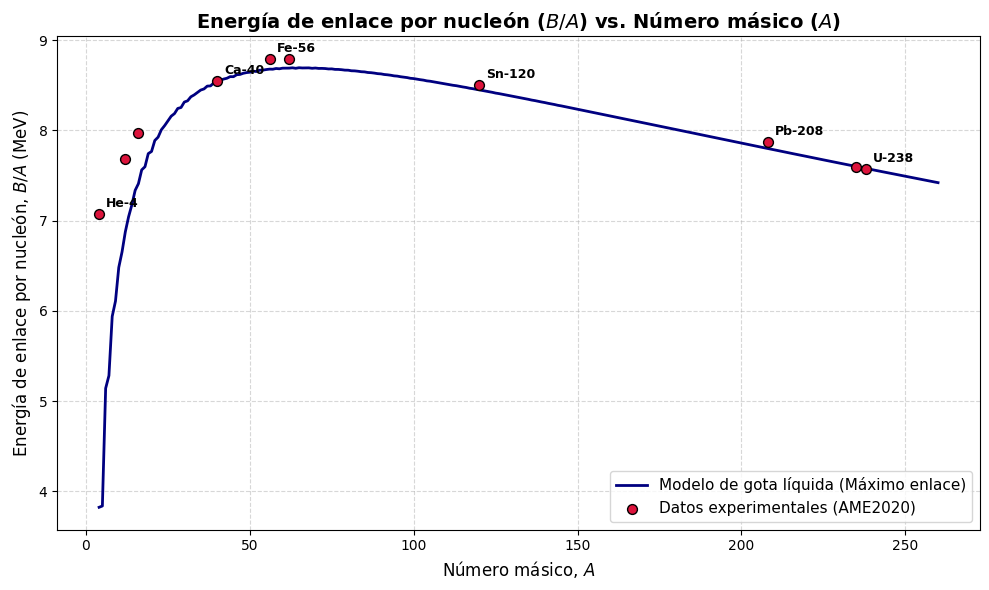

In [52]:
# C.4 -- Uso del módulo de análisis
# Las tres líneas siguientes ya están escritas: agregan la carpeta del Taller a la
# ruta de búsqueda de Python, importan el módulo y lo releen si fue modificado.
import sys, importlib
sys.path.insert(0, "taller_nucleo_atomico")
import analisis_nucleo
_ = importlib.reload(analisis_nucleo)

# Escriba a continuación las llamadas a sus funciones
A_arr, Z_arr, E_B_arr = analisis_nucleo.leer_valle()
A_max, Z_max, EB_max = analisis_nucleo.encontrar_maximo_enlace(A_arr, Z_arr, E_B_arr)
print(f"[Python Corregido] Núcleo más ligado globalmente: A = {A_max}, Z = {Z_max}, E_B = {EB_max:.8f} MeV (B/A = {-EB_max:.8f} MeV)")

# Guardar el resultado corregido
analisis_nucleo.guardar_maximo_python(A_max, Z_max, EB_max)

# Graficar con la escala y datos físicos correctos
analisis_nucleo.graficar_curva_enlace(A_arr, E_B_arr, EXPERIMENTALES)


### PREGUNTA D: VERIFICACION

In [54]:
# ===================== VERIFICACIÓN — NO MODIFICAR =====================
from pathlib import Path
import numpy as np

CARPETA = Path("taller_nucleo_atomico")
veredictos = []

def informar(nombre, condicion, detalle=""):
    veredictos.append(bool(condicion))
    print(f"{'PASS' if condicion else 'FAIL'} | {nombre}" + (f" — {detalle}" if detalle else ""))

def leer_salida(nombre, filas, columnas, origen="fortran"):
    ruta = CARPETA / nombre
    if not ruta.is_file():
        raise ValueError(f"falta {ruta}")
    if origen == "fortran":
        fuentes = [CARPETA / "modulo_nucleo.f90", CARPETA / "programa_nucleo.f90"]
    else:
        fuentes = [CARPETA / "analisis_nucleo.py", CARPETA / "valle.dat"]
    for fuente in fuentes:
        if not fuente.is_file():
            raise ValueError(f"falta {fuente}")
        if ruta.stat().st_mtime < fuente.stat().st_mtime:
            raise ValueError(f"{nombre} es anterior a {fuente.name}: vuelva a ejecutar el cálculo correspondiente")
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape != (filas, columnas) or not np.isfinite(datos).all():
        raise ValueError(f"formato incorrecto en {nombre}: se esperaban {filas} filas y {columnas} columnas finitas")
    return datos

# Implementación de referencia exclusiva de la verificación.
def referencia_terminos(z, a):
    z, a = np.asarray(z, dtype=float), np.asarray(a, dtype=float)
    return np.broadcast_arrays(-15.8 + np.zeros_like(a), 18.3*a**(-1.0/3.0),
                               0.71*z**2*a**(-4.0/3.0), 92.7*(z-a/2.0)**2/a**2)

def referencia_enlace(z, a):
    return sum(referencia_terminos(z, a))

def leer_valle():
    datos = leer_salida("valle.dat", 257, 3)
    if not np.array_equal(datos[:, 0], np.arange(4, 261)):
        raise ValueError("valle.dat debe tener A = 4, 5, ..., 260, en ese orden")
    if not np.array_equal(datos[:, 1], np.rint(datos[:, 1])):
        raise ValueError("los valores de Z deben ser enteros")
    if np.any((datos[:, 1] < 1) | (datos[:, 1] > datos[:, 0])):
        raise ValueError("cada fila debe cumplir 1 <= Z <= A")
    return datos

# 1) Ocho núclidos: todos los términos, el enlace y la masa.
try:
    nuc = leer_salida("nucleos.dat", 8, 8)
    orden = np.array([(94,244), (32,70), (72,179), (18,38), (26,56), (20,40), (92,235), (92,238)])
    if not np.array_equal(nuc[:, :2], orden):
        raise ValueError("Z y A deben ser enteros y seguir el orden del enunciado")
    z, a = orden[:, 0], orden[:, 1]
    terminos = np.column_stack(referencia_terminos(z, a))
    eb = terminos.sum(axis=1)
    masa = z*938.78 + (a-z)*939.57 + a*eb
    ok = (np.allclose(nuc[:, 2:6], terminos, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 6], eb, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 7], masa, rtol=0, atol=1e-3)
          and np.allclose(nuc[:, 2:6].sum(axis=1), nuc[:, 6], rtol=0, atol=1e-7))
    informar("Caso 1: ocho núclidos", ok, f"Pu-244: E_B = {nuc[0,6]:.8f} MeV; M = {nuc[0,7]:.4f} MeV")
except Exception as error:
    informar("Caso 1: ocho núclidos", False, str(error))

# 2) La búsqueda obtiene el máximo enlace para cada A del intervalo.
try:
    valle = leer_valle()
    correctos = []
    for a, z, eb in valle:
        candidatos = np.arange(1, int(a)+1)
        energias = referencia_enlace(candidatos, a)
        correctos.append(abs(float(referencia_enlace(z, a)) - energias.min()) <= 1e-7)
    fila = valle[valle[:, 0] == 208][0]
    ok = all(correctos) and fila[1] == 82 and abs(fila[2] - (-7.800561449221129)) <= 1e-7
    informar("Caso 2: máximo enlace para cada A", ok, f"{sum(correctos)}/257 búsquedas correctas; A=208: Z={fila[1]:.0f}")
except Exception as error:
    informar("Caso 2: máximo enlace para cada A", False, str(error))

# 3) Energías de todas las filas y referencia de U-238.
try:
    valle = leer_valle()
    esperado = referencia_enlace(valle[:, 1], valle[:, 0])
    fila = valle[valle[:, 0] == 238][0]
    ok = (np.allclose(valle[:, 2], esperado, rtol=0, atol=1e-7)
          and fila[1] == 92 and abs(fila[2] - (-7.579586363043683)) <= 1e-7)
    informar("Caso 3: energías de la curva y U-238", ok, f"A=238: Z={fila[1]:.0f}; E_B={fila[2]:.8f} MeV")
except Exception as error:
    informar("Caso 3: energías de la curva y U-238", False, str(error))

# 4) Mínimo global: dos lenguajes y archivo de imagen.
try:
    valle = leer_valle()
    mf = leer_salida("maximo.dat", 1, 3)[0]
    mp = leer_salida("maximo_python.dat", 1, 3, origen="python")[0]
    referencia = valle[np.argmin(valle[:, 2])]
    def coincide(fila):
        return (np.array_equal(fila[:2], referencia[:2])
                and abs(fila[2]-referencia[2]) <= 1e-7)
    imagen = CARPETA / "curva_enlace.png"
    png_ok = (imagen.is_file() and imagen.stat().st_size > 8
              and imagen.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n")
    ok = (coincide(mf) and coincide(mp)
          and abs(referencia[2] - (-8.69506905766211)) <= 1e-7 and png_ok)
    informar("Caso 4: mínimo global e imagen", ok,
             f"Fortran: A={mf[0]:.0f}, Z={mf[1]:.0f}; Python: A={mp[0]:.0f}, Z={mp[1]:.0f}; PNG: {'presente' if png_ok else 'falta o formato incorrecto'}")
except Exception as error:
    informar("Caso 4: mínimo global e imagen", False, str(error))

print(f"\nResumen: {sum(veredictos)}/4 PASS")
print("La arquitectura, los requisitos y la interpretación se revisan por separado.")


PASS | Caso 1: ocho núclidos — Pu-244: E_B = -7.53611738 MeV; M = 227342.0074 MeV
PASS | Caso 2: máximo enlace para cada A — 257/257 búsquedas correctas; A=208: Z=82
PASS | Caso 3: energías de la curva y U-238 — A=238: Z=92; E_B=-7.57958636 MeV
PASS | Caso 4: mínimo global e imagen — Fortran: A=65, Z=29; Python: A=65, Z=29; PNG: presente

Resumen: 4/4 PASS
La arquitectura, los requisitos y la interpretación se revisan por separado.


### PREGUNTA E

1. Usando `nucleos.dat`, elija un núcleo relativamente liviano y otro pesado e identifíquelos. Compare los términos de superficie y Coulomb en ambos casos. ¿Cuál de esos dos términos penaliza más el enlace en cada uno? Explique cómo su competencia contribuye a que la curva $B/A$ presente un máximo.

NUCLEO LIVIANO:

$^{40}\text{Ca}$ ($Z=20, A=40$$Z=20, A=40$).

Término de Superficie: $18.3 \times 40^{-1/3} \approx 5.35\text{ MeV}$.

Término de Coulomb: $0.71 \times 20^2 \times 40^{-4/3} \approx 2.08\text{ MeV}$.

NUCLEO PESADO:

$^{238}\text{U}$ ($Z=92, A=238$$Z=92, A=238$).

Término de Superficie: $18.3 \times 238^{-1/3} \approx 2.95\text{ MeV}$.

Término de Coulomb: $0.71 \times 92^2 \times 238^{-4/3} \approx 4.07\text{ MeV}$.


#### COMPARACION
Núcleos livianos ($A=40$): El término de superficie penaliza más el enlace ($\approx 5.35\text{ MeV}$) en comparación con el término de Coulomb ($\approx 2.08\text{ MeV}$).

Núcleos pesados ($^{238}\text{U}$): El efecto se invierte; la repulsión electrostática del término de Coulomb domina de manera significativa ($\approx 4.07\text{ MeV}$) frente al término de superficie ($\approx 2.95\text{ MeV}$).

La competencia entre el decaimiento de la penalización de superficie ($A^{-1/3}$) y el crecimiento de la penalización de Coulomb ($A^{2/3}$) genera el comportamiento de campana de la curva, a medida que el núcleo es más pesado, la repulsión de Coulomb cobra mayor protagonismo que la penalización por superficie, ademas, alcanza un óptimo o máximo intermedio (cerca de $A \approx 60$$A \approx 60$) donde ambas penalizaciones sumadas logran su valor mínimo.


2. El modelo predice su mayor enlace por nucleón en un $A$ distinto del ${}^{62}$Ni experimental. Calcule la diferencia de $E_B$ entre el máximo del modelo y el punto de su curva con $A=62$. Exprese también la diferencia como porcentaje de la magnitud de $E_B$ en ese punto. Discuta el tamaño de la diferencia y las limitaciones del modelo que podrían contribuir a ella. Distinga esta comparación entre puntos de la curva de una comparación directa con el núclido experimental: para esta última debe usar $Z=28$, $A=62$.

Cálculos en el modelo de 4 términos:

Máximo global del modelo: Se ubica en
$A=65, Z=29$ ($^{65}\text{Cu}$$^{65}\text{Cu}$)

$E_B \approx -8.69507\text{ MeV}$

($B/A \approx 8.69507\text{ MeV}$).

Punto de la curva teórica:

$A=62$ ($Z_{estable}=28$):
El modelo predice $E_B \approx -8.69176\text{MeV}$

($B/A \approx 8.69176\text{ MeV}$).

Diferencia absoluta en la curva:

 $|E_B(29,65) - E_B(28,62)| \approx 0.00331\text{ MeV}$ ($3.31\text{ keV}$).

Diferencia porcentual: $\approx 0.038\%$.

Comparación directa con el núclidoexperimental   ($^{62}\text{Ni}$):

El valor experimental de $B/A$$B/A$ para $^{62}\text{Ni}$ es $8.7945\text{ MeV}$

($E_B = -8.7945\text{ MeV}$).

La predicción del modelo para $Z=28, A=62$ es $E_B \approx -8.69176\text{ MeV}$.

Diferencia absoluta con el experimento: $|-8.7945 - (-8.69176)| \approx 0.1027\text{ MeV}$

($102.7\text{ keV}$$102.7\text{ keV}$ o un $\approx 1.17\%$).

Limitaciones del modelo:

El modelo de la gota liquida es de caracter macroscopico y semiempirico, que, trata al nucleo como un fluido continuo y homogenio. Ignorando los efectos cuanticos que causan que núcleos con $Z, N = 20, 28, 50, 82$ (como el $^{56}\text{Fe}$) tengan capas cerradas sumamente estables y, por ende, un enlace extra de origen microscópico que la gota clásica no puede reproducir.






3. Para $A=56$, ¿qué $Z$ tiene el mayor enlace por nucleón en el modelo de cuatro términos? Compárelo con el hierro ($Z=26$): calcule la diferencia de energía **total**, indicando el orden de la resta, y diga cuál resulta más ligado.

   La fórmula completa incluye un quinto término, el de **apareamiento**: protones y neutrones tienden a formar pares. En la energía total, la corrección vale $-a_P A^{-1/2}$ si $Z$ y $N$ son ambos pares, $+a_P A^{-1/2}$ si ambos son impares, y cero si $A$ es impar, con $a_P\approx12$ MeV. Calcule la corrección para los dos núcleos comparados y determine si invierte su orden de enlace. Recuerde que esta corrección es de energía **total**: para sumarla a $E_B$ debe dividirla entre $A$.

   Este es un **cálculo adicional de comparación**: no incorpore el apareamiento a las funciones del modelo base ni regenere con él los archivos de D. Basta comparar los dos candidatos; no se pide repetir la búsqueda global con el modelo ampliado.

####Sin Apareamiento (Modelo Base):

Para $A=56$ el modelo de 4 términos predice que el núcleo más ligado es el $^{56}\text{Ni}$ ($Z=28$) con
$E_B \approx -8.6816\text{ MeV}$ por nucleón.

Para el Hierro $^{56}\text{Fe}$ ($Z=26$) es de $E_B \approx -8.6725\text{ MeV}$.

El níquel resulta más ligado en este modelo.

Diferencia de Energía Total:
$E_{tot}(26, 56) - E_{tot}(28, 56) = [56 \times (-8.6725)] - [56 \times (-8.6816)] \approx 0.51\text{ MeV}$.

El $^{56}\text{Ni}$ es unos $0.51\text{ MeV}$ más ligado.

####Con el Término de Apareamiento
(Corrección $\delta = a_p A^{-1/2}$ con $a_p = 12\text{ MeV}$)

Para $^{56}\text{Ni}$ ($Z=28$ par, $N=28$ par): El apareamiento es favorable ya que Z y N son pares, por lo que la corrección a la energía total es negativa: $\delta_{Ni}\approx -1.60356\text{ MeV}$.

Para $^{56}\text{Fe}$ ($Z=26$ par, $N=30$ par): También es un núcleo par-par, por lo que su corrección es idéntica: $\delta_{Fe}\approx -1.60356\text{ MeV}$

Conclusión: Dado que ambos núcleos son par-par, reciben exactamente el mismo beneficio energético del apareamiento ($\approx -1.60\text{ MeV}$ de energía total). Por lo tanto , la diferencia de energía neta sigue intacta y la corrección no invierte el orden de enlace. El $^{56}\text{Ni}$ sigue siendo el más ligado en el modelo matemático ampliado.

4. Reutilizando las funciones de su módulo, calcule la energía liberada en la fisión simétrica idealizada ${}^{236}\mathrm{U}\to2\,{}^{118}\mathrm{Pd}$ ($Z=46$): $Q=M(92,236)-2M(46,118)$. Las masas se utilizan aquí como energías equivalentes en MeV. Como ambos lados tienen el mismo número total de protones, las masas electrónicas incluidas se cancelan en esta diferencia, dentro de la aproximación adoptada. Si $Q>0$, el canal es energéticamente favorable. Compárelo con la escala típica de unos 200 MeV por fisión del uranio y explique por qué este canal idealizado no reproduce todos los productos ni el reparto de energía de una fisión real.

####Cálculo con el módulo de masas del taller:

Masa teórica del $^{236}\text{U}$:
$M(92,236) \approx 219793.856\text{ MeV}$.

Masa teórica del $^{118}\text{Pd}$:
$M(46,118)\approx 109804.836\text{ MeV}$.

Valor Q:

$Q = M(92,236) - 2 \times M(46,118) \approx 184.18\text{ MeV}$.


Análisis del Canal Favorable ($Q > 0 Q > 0$):

Como $Q \approx 184\text{ MeV} > 0$$Q \approx 184\text{ MeV} > 0$, la fisión simétrica es muy favorable energéticamente, y el valor se aproxima de forma notable a la escala experimental  de $\approx 200\text{ MeV}$ por evento.

####¿Por qué la realidad difiere de este canal idealizado?
Fisión Asimétrica: En la realidad física, el $^{236}\text{U}$ prefiere fisionarse de manera asimétrica, debido a que estos productos tienen capas cuánticas casi mágicas ($Z=50, N=82$), lo cual es más estable.

####Emisión de Neutrones:
Una fisión real siempre libera de 2 a 3 neutrones rápidos libres,los cuales se llevan parte de la masa del sistema.

####Reparto de Energía:
La energía de fisión no solo se libera en masa de reposo de los núcleos hijos estáticos, sino mayormente en forma de energía cinética de los fragmentos, radiación gamma instantánea y energías de decaimientos beta subsecuentes.